<!-- Run from the repository root; see README.md for Jupyter and Colab setup. -->

# Foreign Direct Investment and Business Investment in Canada, 1981–2018

Replication notebook for *Foreign Direct Investment and Business Investment in Canada* (Porokmi Sambahamphe, revised November 2026).
The full set of checks is in the Extended Working Paper and `extended/` in this repository.

Run top to bottom. Sections follow the paper:

1. Setup
2. Data: download, capacity gap (HP filter), save
3. Figure 1: the data (C$)
4. Unit-root tests (Table 1)
5. Cointegration sensitivity
6. Baseline Canadian-dollar change equation (Table 2)
7. Sensitivity of the FDI coefficient sum (Table 3)
8. Currency bridge between the US$ and C$ specifications
9. Capacity interaction
10. Figure 2: the FDI coefficient sum across specifications
11. Export tables

## 1. Setup

In [1]:
# Set REBUILD_DATA = True to download fresh data from Statistics Canada and the World Bank.
# With False, the notebook uses the saved CSV files in data/ (reproduces the paper exactly).
REBUILD_DATA = False
# Set FETCH_SOURCE_CHECKS = False to skip the comparisons with current Statistics Canada FDI series (needs internet).
FETCH_SOURCE_CHECKS = True

import os, io, zipfile, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.regression.linear_model import GLSAR
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
import itertools, json, urllib.request
import statsmodels.api as sm

DATA_DIR, FIG_DIR, TAB_DIR = "data", "figures", "tables"
for folder in (DATA_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(folder, exist_ok=True)

HAC = dict(cov_type="HAC", cov_kwds={"maxlags": 3})   # Newey-West, 3 lags

## 2. Data

* **Business investment (I)**, nominal and real GDP: Statistics Canada Table 36-10-0222-01 (CAD millions).
* **Gross national expenditure (Y)**, **FDI net inflows**, **exchange rate** (CAD per USD): World Bank WDI.
* **Capacity slack (U)**: potential output from an HP filter (λ = 100) on log real GDP over the full available series;
  U = potential − actual, valued at nominal GDP. Positive U means output is below potential.

Two samples are saved: 1981–2018 (main) and 1981–2024 (extension). All money values are in billions.

In [2]:
def build_dataset(start, end, statcan_table):
    t = statcan_table

    def statcan_series(prices, label):
        s = t[(t["GEO"] == "Canada") & (t["Prices"] == prices) &
              (t["Estimates"] == label) & (t["UOM"] == "Dollars")].copy()
        s["year"] = s["REF_DATE"].astype(int)
        s = s.set_index("year")["VALUE"]                     # CAD millions
        assert s.index.is_unique, f"duplicate years for {label}"
        return s

    gdp_label = "Gross domestic product at market prices"
    real_gdp = statcan_series("Chained (2017) dollars", gdp_label)
    nom_gdp  = statcan_series("Current prices", gdp_label)
    bgfcf    = statcan_series("Current prices", "Business gross fixed capital formation")

    # Potential output: HP filter on log real GDP, using all available years
    cycle, trend = hpfilter(np.log(real_gdp.dropna()), lamb=100)
    gap = np.exp(cycle) - 1                                  # actual / potential - 1
    U_cad_mil = nom_gdp / (1 + gap) - nom_gdp                # potential - actual

    codes = {"NE.DAB.TOTL.CD": "Y_usd", "BX.KLT.DINV.CD.WD": "FDI_usd", "PA.NUS.FCRF": "fx"}
    w = wb.data.DataFrame(list(codes), "CAN", time=range(start, end + 1),
                          columns="series", numericTimeKeys=True).rename(columns=codes)

    df = pd.DataFrame(index=w.index)
    df.index.name = "year"
    df["fx"] = w["fx"]
    df["gap_pct"] = (100 * gap).reindex(df.index)
    # US$ billions
    df["I_usd"]   = bgfcf.reindex(df.index) / df["fx"] / 1000
    df["U_usd"]   = U_cad_mil.reindex(df.index) / df["fx"] / 1000
    df["Y_usd"]   = w["Y_usd"] / 1e9
    df["FDI_usd"] = w["FDI_usd"] / 1e9
    # CAD billions
    df["I_cad"]   = bgfcf.reindex(df.index) / 1000
    df["U_cad"]   = U_cad_mil.reindex(df.index) / 1000
    df["Y_cad"]   = df["Y_usd"] * df["fx"]
    df["FDI_cad"] = df["FDI_usd"] * df["fx"]
    return df

# Automatically rebuild data if CSVs do not exist
missing_files = not (os.path.exists(f"{DATA_DIR}/fdi_data_1981_2018.csv") and
                     os.path.exists(f"{DATA_DIR}/fdi_data_1981_2024.csv"))

if REBUILD_DATA or missing_files:
    !pip install -q wbgapi
    import requests, wbgapi as wb
    url = "https://www150.statcan.gc.ca/n1/tbl/csv/36100222-eng.zip"
    z = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=120).content))
    statcan = pd.read_csv(z.open("36100222.csv"), low_memory=False)
    for start, end in [(1981, 2018), (1981, 2024)]:
        build_dataset(start, end, statcan).to_csv(f"{DATA_DIR}/fdi_data_{start}_{end}.csv")

base = pd.read_csv(f"{DATA_DIR}/fdi_data_1981_2018.csv", index_col="year")
ext  = pd.read_csv(f"{DATA_DIR}/fdi_data_1981_2024.csv", index_col="year")
print("Main sample:", base.shape, "| Extended sample:", ext.shape)
print("Missing values (main):", int(base.isna().sum().sum()))
base.round(2)

Main sample: (38, 10) | Extended sample: (44, 10)
Missing values (main): 0


,fx,gap_pct,I_usd,U_usd,Y_usd,FDI_usd,I_cad,U_cad,Y_cad,FDI_cad
year,,,,,,,,,,
1981,1.20,2.65,65.00,-7.94,305.51,0.66,77.93,-9.52,366.27,0.80
1982,1.23,-3.27,58.24,10.62,303.65,0.09,71.85,13.10,374.62,0.11
1983,1.23,-3.47,58.68,12.30,331.98,4.62,72.32,15.16,409.14,5.69
1984,1.30,-0.57,58.22,2.04,345.07,5.68,75.40,2.64,446.89,7.35
1985,1.37,1.33,61.26,-4.79,357.79,1.26,83.65,-6.54,488.57,1.72
1986,1.39,0.75,65.47,-2.81,376.16,2.71,90.98,-3.91,522.66,3.77
1987,1.33,2.20,79.32,-9.30,427.41,8.60,105.18,-12.34,566.74,11.40
1988,1.23,4.14,97.20,-20.25,504.77,7.20,119.63,-24.92,621.23,8.86
1989,1.18,4.16,109.68,-22.65,566.29,7.17,129.85,-26.82,670.47,8.49


### Analysis variables

Canadian dollars are the primary unit: converting at a time-varying exchange rate adds a revaluation component to every annual change.
`prep()` creates **I, Y, U, FDI** in the chosen currency, expenditure net of business investment **N = Y − I**, the expenditure control **X**
(Y or N), first differences **dI, dX**, lagged FDI **FDI_l1**, the lagged error-correction term **ECT**, percent slack **S** (= −gap_pct,
positive below potential), a linear trend **t**, and single-year indicators.

In [3]:
def prep(data, unit="cad", x="Y"):
    d = data.copy()
    d["I"], d["Y"] = d[f"I_{unit}"], d[f"Y_{unit}"]
    d["U"], d["FDI"] = d[f"U_{unit}"], d[f"FDI_{unit}"]
    d["N"] = d["Y"] - d["I"]
    d["X"] = d[x]
    d["dI"], d["dX"] = d["I"].diff(), d["X"].diff()
    d["FDI_l1"] = d["FDI"].shift(1)
    d["dI_l1"], d["dX_l1"] = d["dI"].shift(1), d["dX"].shift(1)
    d["ECT"] = smf.ols("I ~ X", data=d).fit().resid.shift(1)
    d["S"] = -d["gap_pct"]
    d["t"] = np.arange(len(d))
    for yr in (2001, 2009, 2020):
        d[f"y{yr}"] = (d.index == yr).astype(int)
    return d

BASELINE = "dI ~ dX + U + FDI + FDI_l1"
fmt_p = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"

def bg(m):
    """Two-lag Breusch-Godfrey p-value (on the OLS fit of the same design)."""
    return acorr_breusch_godfrey(sm.OLS(m.model.endog, m.model.exog).fit(), nlags=2)[1]

def fdi_sum(m):
    """Coefficient sum delta0 + delta1 with its 95% interval and p-value, plus the timing tests."""
    t = m.t_test("FDI + FDI_l1 = 0"); lo, hi = t.conf_int()[0]
    return {"d0": m.params["FDI"], "d1": m.params["FDI_l1"], "sum": float(t.effect[0]), "lo": lo, "hi": hi,
            "p_sum": float(t.pvalue), "p_d1": m.wald_test("FDI_l1 = 0", scalar=True).pvalue, "BG p": bg(m), "N": int(m.nobs)}

cad, cad_n, cad_ext = prep(base), prep(base, x="N"), prep(ext)

## 3. Figure 1: investment, FDI and the output gap (C$)

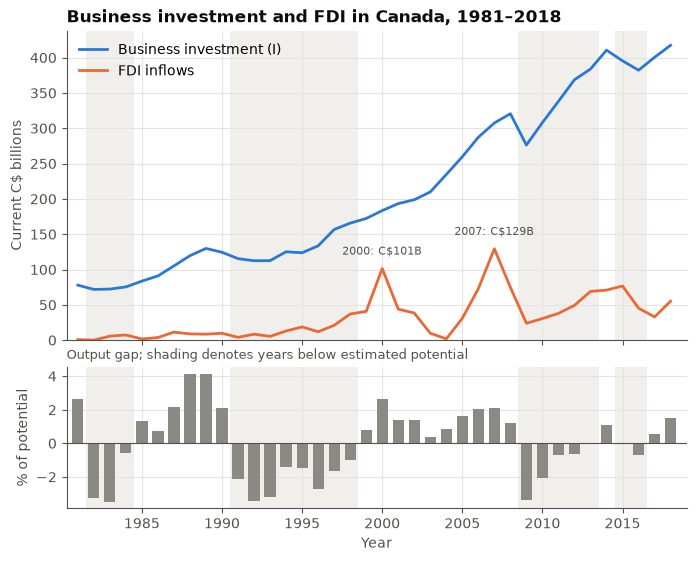

In [4]:
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.2), sharex=True,
                             gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.12})
for ax in (a1, a2):                                   # shade years below potential
    for yr in base.index[base["gap_pct"] < 0]:
        ax.axvspan(yr - 0.5, yr + 0.5, color="#f0efec", lw=0, zorder=0)

a1.plot(base.index, base["I_cad"], color=BLUE, lw=2, label="Business investment (I)")
a1.plot(base.index, base["FDI_cad"], color=ORANGE, lw=2, label="FDI inflows")
for yr in (2000, 2007):
    a1.annotate(f"{yr}: C${base.loc[yr, 'FDI_cad']:.0f}B", xy=(yr, base.loc[yr, "FDI_cad"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=INK2)
a1.set_ylabel("Current C$ billions"); a1.set_ylim(0, None); a1.legend(loc="upper left")
a1.set_title("Business investment and FDI in Canada, 1981–2018", loc="left", fontsize=12, fontweight="bold")

a2.bar(base.index, base["gap_pct"], color=GRAY, width=0.7)
a2.axhline(0, color=INK2, lw=0.8)
a2.set_ylabel("% of potential"); a2.set_xlabel("Year"); a2.set_xlim(1980.3, 2019.0)
a2.set_title("Output gap; shading denotes years below estimated potential", loc="left", fontsize=9, color=INK2)

fig.savefig(f"{FIG_DIR}/figure1_data.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Unit-root tests (Table 1)

Augmented Dickey–Fuller, lag length by AIC. Levels are tested with a constant and trend; FDI and U, which enter the baseline equation in
levels, are also tested with a constant only, because rejection around a trend does not establish stationarity around a constant.

In [5]:
rows = []
for v in ["I", "Y", "U", "FDI"]:
    ct = adfuller(cad[v].dropna(), regression="ct", autolag="AIC")[1]
    c = adfuller(cad[v].dropna(), regression="c", autolag="AIC")[1]
    dif = adfuller(cad[v].diff().dropna(), regression="c", autolag="AIC")[1]
    rows.append({"Variable": v, "p (level, constant + trend)": fmt_p(ct), "p (level, constant only)": fmt_p(c),
                 "p (first difference)": fmt_p(dif)})
table1 = pd.DataFrame(rows).set_index("Variable")
trend_fdi = smf.ols("FDI ~ t", data=cad).fit(**HAC)
print(f"FDI linear trend: {trend_fdi.params['t']:.2f} C$ bn per year (p = {fmt_p(trend_fdi.pvalues['t'])})")
table1

FDI linear trend: 1.84 C$ bn per year (p = <0.001)


,"p (level, constant + trend)","p (level, constant only)",p (first difference)
Variable,,,
I,0.543,0.992,<0.001
Y,0.970,1.000,<0.001
U,0.010,0.004,<0.001
FDI,<0.001,0.849,<0.001


## 5. Cointegration sensitivity

Engle–Granger test of I and expenditure under two lag-selection settings (default AIC; maximum three lags with BIC).
In C$ the conclusion depends on the setting, so the baseline does not rely on an error-correction term.

In [6]:
rows = []
for unit in ["cad", "usd"]:
    for x in ["Y", "N"]:
        d = prep(base, unit, x)
        rows.append({"Currency": unit.upper(), "Expenditure": x,
                     "p (default AIC)": fmt_p(coint(d["I"], d["X"], trend="c")[1]),
                     "p (BIC, max 3 lags)": fmt_p(coint(d["I"], d["X"], trend="c", maxlag=3, autolag="bic")[1])})
pd.DataFrame(rows)

,Currency,Expenditure,p (default AIC),"p (BIC, max 3 lags)"
0,CAD,Y,0.382,0.023
1,CAD,N,0.394,0.024
2,USD,Y,0.002,0.002
3,USD,N,0.002,0.007


## 6. Baseline Canadian-dollar change equation (Table 2)

ΔI = κ + θΔX + γU + δ₀FDI + δ₁FDI₋₁ + e, with Newey–West (HAC, 3 lags) standard errors. Columns (3)–(4) add a linear trend.
The trend-free equation is the baseline as a presentation choice; the comparison is not evidence that either is statistically superior.

In [7]:
specs = {"(1) Total expenditure": (cad, ""), "(2) Excl. investment": (cad_n, ""),
         "(3) (1) + trend": (cad, " + t"), "(4) (2) + trend": (cad_n, " + t")}
baseline = {k: smf.ols(BASELINE + extra, data=d).fit(**HAC) for k, (d, extra) in specs.items()}
rows = []
for var, label in [("dX", "ΔX"), ("U", "U"), ("FDI", "FDI (δ₀)"), ("FDI_l1", "FDI₋₁ (δ₁)"), ("t", "Trend"), ("Intercept", "Intercept")]:
    rows.append([label] + [f"{m.params[var]:.3f}" if var in m.params else "" for m in baseline.values()])
    rows.append([""] + [f"({m.bse[var]:.3f})" if var in m.params else "" for m in baseline.values()])
S = [fdi_sum(m) for m in baseline.values()]
rows += [["δ₀ + δ₁"] + [f"{r['sum']:.3f}" for r in S],
         ["95% interval"] + [f"[{r['lo']:.3f}, {r['hi']:.3f}]" for r in S],
         ["p, δ₀ + δ₁ = 0"] + [fmt_p(r["p_sum"]) for r in S],
         ["p, δ₁ = 0"] + [fmt_p(r["p_d1"]) for r in S],
         ["Breusch–Godfrey p"] + [fmt_p(r["BG p"]) for r in S],
         ["N"] + [str(r["N"]) for r in S]]
table2 = pd.DataFrame(rows, columns=["", *baseline]).set_index("")
m0 = baseline["(1) Total expenditure"]
print("Differences restriction (δ₀ + δ₁ = 0) p:", fmt_p(S[0]["p_sum"]), "| levels restriction (δ₁ = 0) p:", fmt_p(S[0]["p_d1"]))
table2

Differences restriction (δ₀ + δ₁ = 0) p: <0.001 | levels restriction (δ₁ = 0) p: 0.089


,(1) Total expenditure,(2) Excl. investment,(3) (1) + trend,(4) (2) + trend
,,,,
ΔX,0.431,0.417,0.491,0.365
,(0.053),(0.155),(0.032),(0.195)
U,-0.002,-0.123,0.064,-0.157
,(0.061),(0.113),(0.060),(0.111)
FDI (δ₀),-0.015,0.063,0.014,0.048
,(0.057),(0.087),(0.065),(0.088)
FDI₋₁ (δ₁),-0.116,-0.198,-0.064,-0.219
,(0.068),(0.103),(0.066),(0.097)
Trend,,,-0.326,0.173


## 7. Sensitivity of the FDI coefficient sum (Table 3)

Alternative specifications: expenditure excluding investment, trend, ECM variant, 1981–2024 with a 2020 indicator, extra short-run
dynamics, Statistics Canada's own FDI series (current releases; `FETCH_SOURCE_CHECKS`), and the US$ comparison.

In [8]:
common = cad.dropna(subset=["dI_l1", "dX_l1", "FDI_l1", "dI", "dX"])
models = {
    "Baseline, total expenditure": smf.ols(BASELINE, data=cad).fit(**HAC),
    "Excl. business investment (N)": smf.ols(BASELINE, data=cad_n).fit(**HAC),
    "+ trend": smf.ols(BASELINE + " + t", data=cad).fit(**HAC),
    "+ trend, N": smf.ols(BASELINE + " + t", data=cad_n).fit(**HAC),
    "ECM variant": smf.ols(BASELINE + " + ECT", data=cad).fit(**HAC),
    "ECM variant, N": smf.ols(BASELINE + " + ECT", data=cad_n).fit(**HAC),
    "1981–2024 + 2020 indicator": smf.ols(BASELINE + " + y2020", data=cad_ext).fit(**HAC),
    "1981–2024 + 2020 indicator, N": smf.ols(BASELINE + " + y2020", data=prep(ext, x="N")).fit(**HAC),
    "+ lagged ΔI and ΔX (1983–2018)": smf.ols(BASELINE + " + dI_l1 + dX_l1", data=common).fit(**HAC),
}

def statcan(table):
    raw = urllib.request.urlopen(f"https://www150.statcan.gc.ca/n1/tbl/csv/{table}-eng.zip", timeout=300).read()
    return pd.read_csv(zipfile.ZipFile(io.BytesIO(raw)).open(f"{table}.csv"), low_memory=False)

if FETCH_SOURCE_CHECKS:
    try:
        a = statcan("36100471")
        liab = (a[(a.GEO == "Canada") & (a["Financial account"] == "Direct investment liabilities")
                  & (a["Countries or regions"] == "All countries")]
                .assign(year=lambda z: z.REF_DATE.astype(int)).set_index("year")["VALUE"] / 1000)
        q = statcan("36100442")
        q = q[(q["Asset liability and directional direct investment presentations"]
               == "Equals: Foreign direct investment in Canada (directional presentation)") & (q["Geographic region"] == "All countries")]
        q = q.assign(year=q.REF_DATE.str[:4].astype(int))
        directional = (q.groupby("year")["VALUE"].sum() / 1000)[q.groupby("year").size() == 4]
        def with_fdi(series, start):
            z = base.loc[start:2018].copy(); z["FDI_cad"] = series.reindex(z.index); return prep(z)
        models["StatCan direct investment liabilities"] = smf.ols(BASELINE, data=with_fdi(liab, 1981)).fit(**HAC)
        models["Archived FDI, 1991–2018"] = smf.ols(BASELINE, data=with_fdi(base["FDI_cad"], 1990)).fit(**HAC)
        models["StatCan directional inward FDI, 1991–2018"] = smf.ols(BASELINE, data=with_fdi(directional, 1990)).fit(**HAC)
    except Exception as err:
        print("Source checks skipped:", err)

models["US$ change equation"] = smf.ols(BASELINE, data=prep(base, "usd")).fit(**HAC)
sens = pd.DataFrame({k: fdi_sum(m) for k, m in models.items()}).T
table3 = pd.DataFrame({"δ₀ + δ₁": sens["sum"].map("{:.3f}".format),
                       "95% interval": [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in zip(sens["lo"], sens["hi"])],
                       "p": sens["p_sum"].map(fmt_p), "BG p": sens["BG p"].map(fmt_p), "N": sens["N"].astype(int)})
loo = pd.Series({yr: smf.ols(BASELINE, data=cad.dropna(subset=["dI", "FDI_l1"]).drop(yr)).fit().params[["FDI", "FDI_l1"]].sum()
                 for yr in cad.dropna(subset=["dI", "FDI_l1"]).index})
print(f"Leave-one-out sums: {loo.min():.3f} (omit {loo.idxmin()}) to {loo.max():.3f} (omit {loo.idxmax()})")
table3

Leave-one-out sums: -0.155 (omit 2001) to -0.095 (omit 2009)


,δ₀ + δ₁,95% interval,p,BG p,N
"Baseline, total expenditure",-0.130,"[-0.188, -0.073]",<0.001,0.223,37
Excl. business investment (N),-0.135,"[-0.258, -0.012]",0.031,0.274,37
+ trend,-0.050,"[-0.150, 0.050]",0.324,0.289,37
"+ trend, N",-0.171,"[-0.307, -0.034]",0.014,0.295,37
ECM variant,-0.098,"[-0.153, -0.044]",<0.001,0.149,37
"ECM variant, N",-0.038,"[-0.129, 0.052]",0.407,0.018,37
1981–2024 + 2020 indicator,-0.099,"[-0.194, -0.004]",0.040,0.367,43
"1981–2024 + 2020 indicator, N",-0.081,"[-0.216, 0.054]",0.238,0.567,43
+ lagged ΔI and ΔX (1983–2018),-0.132,"[-0.183, -0.080]",<0.001,0.001,36
StatCan direct investment liabilities,-0.131,"[-0.190, -0.072]",<0.001,0.222,37


## 8. Currency bridge

Multiplying the US$ change equation by e (CAD per USD) gives an exact C$ translation, reproduced by WLS with weights e⁻² and e in place
of the constant. Five adjustments lead to the C$ baseline: remove weights (W), add a constant (C), use C$ changes instead of revalued
changes (V), use unadjusted lagged FDI (L), drop e (E). Each adjustment's contribution is averaged over all 120 orders (Shapley).

In [9]:
def bridge_sum(ops):
    b, e = base, base["fx"]
    y = b["I_cad"].diff() if "V" in ops else e * b["I_usd"].diff()
    X = pd.DataFrame({"dX": b["Y_cad"].diff() if "V" in ops else e * b["Y_usd"].diff(),
                      "U": b["U_cad"], "FDI": b["FDI_cad"],
                      "FDI_l1": b["FDI_cad"].shift(1) * (1 if "L" in ops else e / e.shift(1))})
    if "E" not in ops:
        X["e"] = e
    if "C" in ops:
        X = sm.add_constant(X)
    df = pd.concat([y.rename("y"), X, (e ** -2).rename("w")], axis=1).dropna()
    m = sm.WLS(df["y"], df[X.columns], weights=1 if "W" in ops else df["w"]).fit()
    return m.params["FDI"] + m.params["FDI_l1"]

OPS = "WCVLE"
val = {frozenset(s): bridge_sum(s) for k in range(6) for s in itertools.combinations(OPS, k)}
contrib = {op: [] for op in OPS}
for order in itertools.permutations(OPS):
    cur = frozenset()
    for op in order:
        contrib[op].append(val[cur | {op}] - val[cur]); cur = cur | {op}
print(f"Exact US$ translation: {val[frozenset()]:.3f}  ->  C$ baseline: {val[frozenset(OPS)]:.3f}")
pd.DataFrame({op: {"mean contribution": np.mean(v), "min over orders": min(v), "max over orders": max(v)}
              for op, v in contrib.items()}).T.round(3)

Exact US$ translation: -0.025  ->  C$ baseline: -0.130


,mean contribution,min over orders,max over orders
W,-0.007,-0.015,-0.000
C,0.020,-0.015,0.051
V,-0.096,-0.108,-0.084
L,-0.004,-0.007,-0.002
E,-0.017,-0.041,0.016


## 9. Capacity interaction

Timing-aligned interactions with percent slack S: δ₀FDI + δ₁FDI₋₁ + η₀(FDI × S) + η₁(FDI₋₁ × S). The joint test asks whether either slope
varies with slack; the test of η₀ + η₁ = 0 asks whether the coefficient sum does.

In [10]:
for label, d in [("total expenditure", cad), ("excl. investment", cad_n)]:
    for extra, note in [("", ""), (" + y2001 + y2009", " (+ 2001, 2009 indicators, exploratory)")]:
        m = smf.ols(BASELINE + " + S + FDI:S + FDI_l1:S" + extra, data=d).fit(**HAC)
        joint = m.wald_test("FDI:S = 0, FDI_l1:S = 0", scalar=True).pvalue
        s = m.t_test("FDI:S + FDI_l1:S = 0"); lo, hi = s.conf_int()[0]
        print(f"{label}{note}: eta0 = {m.params['FDI:S']:.3f}, eta1 = {m.params['FDI_l1:S']:.3f}, joint p = {fmt_p(joint)}, "
              f"eta0 + eta1 = {float(s.effect[0]):.3f} [{lo:.3f}, {hi:.3f}], p = {fmt_p(float(s.pvalue))}")

total expenditure: eta0 = 0.055, eta1 = -0.115, joint p = <0.001, eta0 + eta1 = -0.060 [-0.136, 0.015], p = 0.116
total expenditure (+ 2001, 2009 indicators, exploratory): eta0 = 0.070, eta1 = -0.115, joint p = 0.110, eta0 + eta1 = -0.045 [-0.132, 0.042], p = 0.308
excl. investment: eta0 = 0.122, eta1 = -0.188, joint p = <0.001, eta0 + eta1 = -0.066 [-0.174, 0.042], p = 0.231
excl. investment (+ 2001, 2009 indicators, exploratory): eta0 = 0.135, eta1 = -0.186, joint p = 0.035, eta0 + eta1 = -0.051 [-0.200, 0.098], p = 0.503


## 10. Figure 2: the FDI coefficient sum across specifications

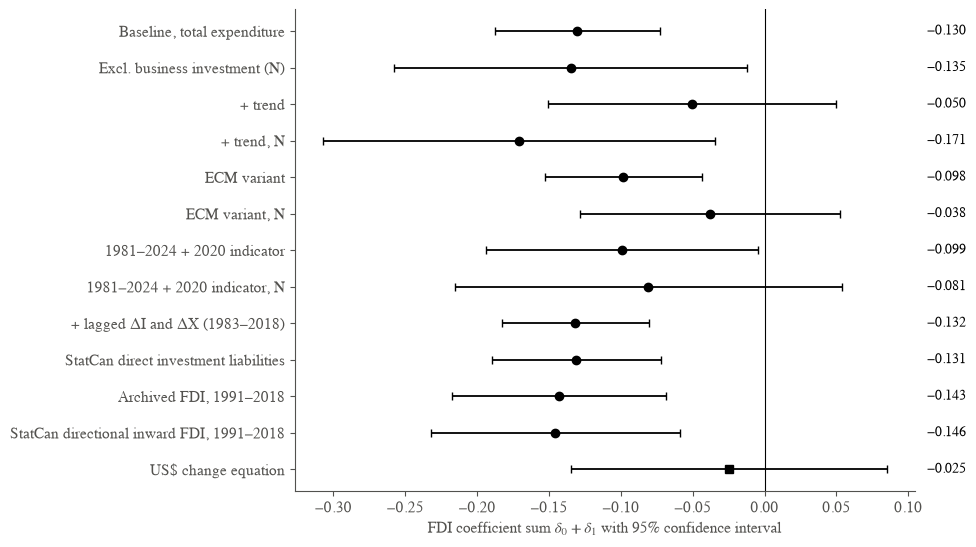

In [11]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times", "STIXGeneral", "DejaVu Serif"], "font.size": 11,
                     "mathtext.fontset": "stix", "axes.grid": False})
fig, ax = plt.subplots(figsize=(8, 0.42 * len(sens) + 0.8))
ypos = np.arange(len(sens))[::-1]
for y, (name, r) in zip(ypos, sens.iterrows()):
    marker = "s" if name.startswith("US$") else "o"
    ax.errorbar(r["sum"], y, xerr=[[r["sum"] - r["lo"]], [r["hi"] - r["sum"]]], fmt=marker, color="black",
                ms=6, capsize=3, lw=1.3)
    ax.text(1.02, y, f"{r['sum']:+.3f}".replace("-", "−"), transform=ax.get_yaxis_transform(), va="center", fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(ypos, sens.index)
ax.set_xlabel(r"FDI coefficient sum $\delta_0 + \delta_1$ with 95% confidence interval")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(f"{FIG_DIR}/figure2_fdi_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Export tables

CSV for each table, plus booktabs-style PNG versions used in the paper.

In [12]:
def table_png(df, title, note, path, index_label=""):
    """Render a table as a booktabs-style image (title, rules, note)."""
    cols = [index_label or df.index.name or ""] + list(df.columns)
    body = [[str(i)] + [str(v) for v in row] for i, row in zip(df.index, df.values)]
    n, k = len(body), len(cols)
    width = [max(len(r[j]) for r in body + [cols]) for j in range(k)]
    x = np.cumsum([0] + [w + 2 for w in width])
    fig = plt.figure(figsize=(0.085 * x[-1], 0.27 * (n + 3.2)))
    ax = fig.add_axes([0, 0, 1, 1]); ax.axis("off")
    H = n + 3.2; X = x[-1]
    fs = {"family": "DejaVu Sans"}
    ax.text(0, H - 0.6, title, fontsize=13, weight="bold", va="center", **fs)
    for yy, lw in [(H - 1.3, 1.6), (H - 2.3, 0.8), (H - 2.3 - n, 1.6)]:
        ax.plot([0, X - 2], [yy, yy], color="black", lw=lw)
    for j, c in enumerate(cols):
        ax.text(x[j] if j == 0 else x[j + 1] - 2, H - 1.8, c, ha="left" if j == 0 else "right", va="center", weight="bold", fontsize=10, **fs)
    for i, r in enumerate(body):
        for j, c in enumerate(r):
            ax.text(x[j] if j == 0 else x[j + 1] - 2, H - 2.8 - i, c, ha="left" if j == 0 else "right", va="center", fontsize=10, **fs)
    ax.text(0, H - 2.9 - n, note, fontsize=8.5, color="#444444", va="center", **fs)
    ax.set_xlim(-0.5, X); ax.set_ylim(H - 3.3 - n, H)
    fig.savefig(path, dpi=250, bbox_inches="tight"); plt.close(fig)

table1.to_csv(f"{TAB_DIR}/table1_adf.csv")
table2.to_csv(f"{TAB_DIR}/table2_main_estimates.csv")
table3.to_csv(f"{TAB_DIR}/table3_robustness.csv")
sens.to_csv(f"{TAB_DIR}/figure2_fdi_coefficients.csv")
table_png(table1, "Table 1. Augmented Dickey–Fuller tests, C$, 1981–2018",
          "Null: unit root. Lag length by AIC. Differences include a constant.", f"{TAB_DIR}/table1_adf.png")
table_png(table2, "Table 2. Baseline Canadian-dollar estimates",
          "Dependent variable ΔI, C$ billions, 1982–2018. X = Y in (1), (3); X = N = Y − I in (2), (4). HAC (3 lags) SEs in parentheses.",
          f"{TAB_DIR}/table2_main_estimates.png")
table_png(table3, "Table 3. Sensitivity of the FDI coefficient sum",
          "C$ unless stated; HAC (3 lags). BG: two-lag Breusch–Godfrey p. StatCan rows use current releases.",
          f"{TAB_DIR}/table3_robustness.png", "Specification")
print(sorted(os.listdir(TAB_DIR)), sorted(os.listdir(FIG_DIR)))

['figure2_fdi_coefficients.csv', 'table1_adf.csv', 'table1_adf.png', 'table2_main_estimates.csv', 'table2_main_estimates.png', 'table3_robustness.csv', 'table3_robustness.png'] ['figure1_data.png', 'figure2_fdi_coefficients.png']
